## Questions to Answer
1. How are ratings distributed across reviews?
2. How has review volume changed over time?
3. Do longer reviews tend to have lower ratings?
4. Do unhappy customers write longer reviews than happy ones?
5. Are there data quality issues to fix before further analysis?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import pandas as pd

df = pd.read_csv("Reviews.csv.zip")
print(df.shape)

(568454, 10)


In [5]:
df = df.sample(50000, random_state=42).reset_index(drop=True)
print(df.shape)

(50000, 10)


In [6]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,165257,B000EVG8J2,A1L01D2BD3RKVO,"B. Miller ""pet person""",0,0,5,1268179200,Crunchy & Good Gluten-Free Sandwich Cookies!,Having tried a couple of other brands of glute...
1,231466,B0000BXJIS,A3U62RE5XZDP0G,Marty,0,0,5,1298937600,great kitty treats,My cat loves these treats. If ever I can't fin...
2,427828,B008FHUFAU,AOXC0JQQZGGB6,Kenneth Shevlin,0,2,3,1224028800,COFFEE TASTE,A little less than I expected. It tends to ha...
3,433955,B006BXV14E,A3PWPNZVMNX3PA,rareoopdvds,0,1,2,1335312000,So the Mini-Wheats were too big?,"First there was Frosted Mini-Wheats, in origin..."
4,70261,B007I7Z3Z0,A1XNZ7PCE45KK7,Og8ys1,0,2,5,1334707200,Great Taste . . .,and I want to congratulate the graphic artist ...


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      50000 non-null  int64 
 1   ProductId               50000 non-null  object
 2   UserId                  50000 non-null  object
 3   ProfileName             50000 non-null  object
 4   HelpfulnessNumerator    50000 non-null  int64 
 5   HelpfulnessDenominator  50000 non-null  int64 
 6   Score                   50000 non-null  int64 
 7   Time                    50000 non-null  int64 
 8   Summary                 49999 non-null  object
 9   Text                    50000 non-null  object
dtypes: int64(5), object(5)
memory usage: 3.8+ MB


In [8]:
print("Before:", df.shape)
df = df.drop_duplicates(subset=["UserId", "ProductId", "Text"])
df = df.dropna(subset=["Text"])
df["Summary"] = df["Summary"].fillna("")
print("After:", df.shape)

Before: (50000, 10)
After: (49976, 10)


In [9]:
df["Time"] = pd.to_datetime(df["Time"], unit="s")
df["year"] = df["Time"].dt.year
df["review_length"] = df["Text"].str.split().str.len()
df[["Time", "year", "review_length"]].head()

,Time,year,review_length
0,2010-03-10,2010,84
1,2011-03-01,2011,99
2,2008-10-15,2008,28
3,2012-04-25,2012,294
4,2012-04-18,2012,122


In [10]:
bad = df[df["HelpfulnessNumerator"] > df["HelpfulnessDenominator"]]
print("Invalid helpfulness rows:", len(bad))
df = df.drop(bad.index)

Invalid helpfulness rows: 1


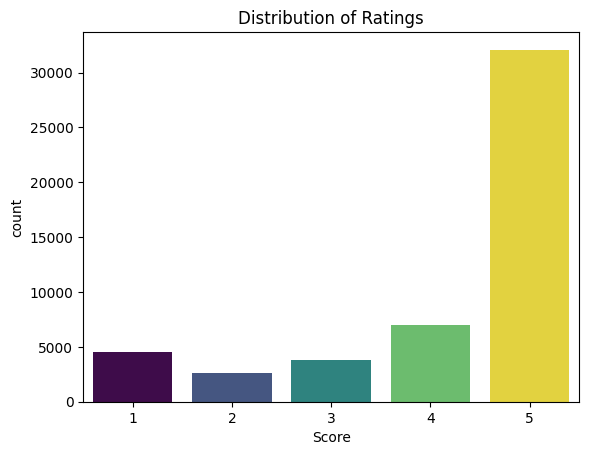

Score
1     9.036518
2     5.154577
3     7.581791
4    14.019010
5    64.208104
Name: proportion, dtype: float64


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Score", data=df, hue="Score", palette="viridis", legend=False)
plt.title("Distribution of Ratings")
plt.show()
print(df["Score"].value_counts(normalize=True).sort_index() * 100)

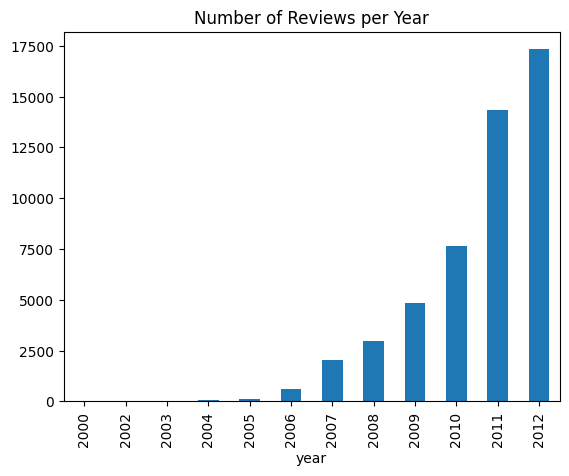

In [14]:
df["year"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Reviews per Year")
plt.show()

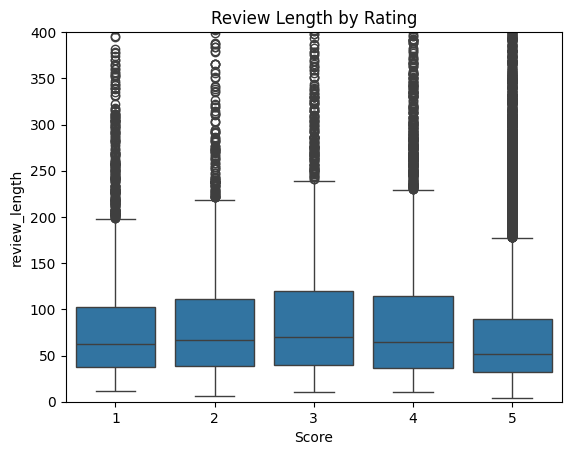

Score
1    85.094553
2    89.107531
3    94.242808
4    91.550671
5    74.181813
Name: review_length, dtype: float64


In [15]:
sns.boxplot(x="Score", y="review_length", data=df)
plt.ylim(0, 400)
plt.title("Review Length by Rating")
plt.show()
print(df.groupby("Score")["review_length"].mean())

In [16]:
from scipy.stats import mannwhitneyu

neg = df[df["Score"] == 1]["review_length"]
pos = df[df["Score"] == 5]["review_length"]

stat, p = mannwhitneyu(neg, pos)
print("Mean length, 1-star:", round(neg.mean(), 1))
print("Mean length, 5-star:", round(pos.mean(), 1))
print("p-value:", p)

Mean length, 1-star: 85.1
Mean length, 5-star: 74.2
p-value: 1.6143823430673584e-37


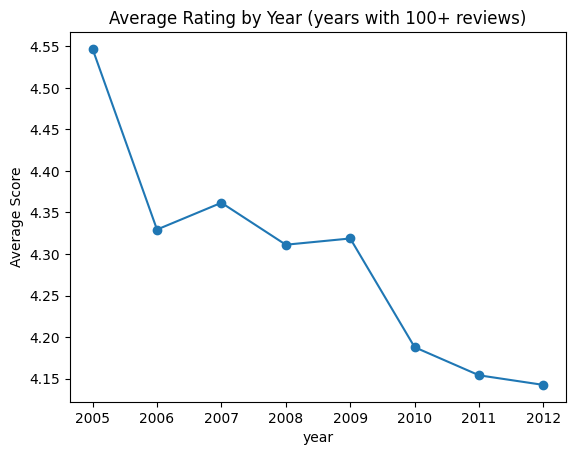

In [19]:
yearly = df.groupby("year")["Score"].agg(["mean", "count"])
yearly = yearly[yearly["count"] >= 100]
yearly["mean"].plot(marker="o")
plt.title("Average Rating by Year (years with 100+ reviews)")
plt.ylabel("Average Score")
plt.show()

In [20]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,year,review_length
count,49975.000000,49975.000000,49975.000000,49975.000000,49975,49975.000000,49975.000000
mean,284584.809705,1.731166,2.208384,4.192076,2011-01-25 09:16:41.660830464,2010.572326,79.893227
min,3.000000,0.000000,0.000000,1.000000,2000-01-19 00:00:00,2000.000000,4.000000
25%,142482.000000,0.000000,0.000000,4.000000,2010-04-11 00:00:00,2010.000000,33.000000
50%,283374.000000,0.000000,1.000000,5.000000,2011-07-17 00:00:00,2011.000000,56.000000
75%,426922.000000,2.000000,2.000000,5.000000,2012-03-24 00:00:00,2012.000000,98.000000
max,568446.000000,454.000000,462.000000,5.000000,2012-10-26 00:00:00,2012.000000,1901.000000
std,164346.596119,7.103677,7.749149,1.304036,NaN,1.536605,78.492648


## EDA Summary

**Key findings**
- Ratings are heavily skewed: 64% are 5-star, and 1-star (9.0%) outnumbers 2-star (5.2%), showing polarized opinions.
- Review volume grew steadily over time (2012 is a partial year; data ends October 2012).
- Average rating declined from about 4.55 (2005) to about 4.14 (2012), suggesting growing customer dissatisfaction or a broader reviewer base over time.
- Review length is right-skewed (median 56 words, mean 79.9, max 1,901).
- Most reviews receive no helpfulness votes (median = 0).
- Hypothesis test (Mann-Whitney U): 1-star reviews (mean 85.1 words) are significantly longer than 5-star reviews (mean 74.2 words), p < 0.05. 3-star reviews are the longest (94.2 words).
- Interpretation: dissatisfied or mixed customers write longer explanations, while satisfied customers write short praise.

**Data issues identified**
- Class imbalance (64% 5-star), which can bias sentiment models.
- Extreme outliers in review length (axis capped at 400 words for readability).
- 24 duplicate reviews and 1 invalid helpfulness record were removed.
- 2012 is a partial year.
- Early years (2000-2003) have very few reviews, so yearly averages there are unreliable.
- Analysis uses a random sample of 50,000 of 568,454 reviews.